# Milestone 1: Exploration & Cleaning

**Dataset:** House Sales in King County, USA (Kaggle, `kc_house_data.csv`)

**Goal:** Load the data, look at it, clean it, and make 3 charts.

**Target variable:** `price` (the sale price of a house).

## Step 1: Import libraries

I import the tools I need.
- `pandas` and `numpy` are for data.
- `matplotlib` and `seaborn` are for charts.

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Make the charts look clean
sns.set_theme(style="whitegrid")

## Step 2: Load the dataset

I read the CSV file from the `data/` folder into a DataFrame called `df`.

In [24]:
df = pd.read_csv(r"C:\data-science-internship\data\kc_house_data.csv\kc_house_data.csv")
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## Step 3: Inspect the basic structure

First, `df.shape` shows the number of rows and columns.

In [25]:
df.shape

(21613, 21)

`df.info()` shows the data type of each column. It also shows how many values are not empty.

In [26]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

## Step 4: Statistical summary

`df.describe()` shows the count, mean, min, max and more for each number column.

In [27]:
df.describe()

,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
count,2.161300e+04,2.161300e+04,21613.000000,21613.000000,21613.000000,2.161300e+04,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000,21613.000000
mean,4.580302e+09,5.400881e+05,3.370842,2.114757,2079.899736,1.510697e+04,1.494309,0.007542,0.234303,3.409430,7.656873,1788.390691,291.509045,1971.005136,84.402258,98077.939805,47.560053,-122.213896,1986.552492,12768.455652
std,2.876566e+09,3.671272e+05,0.930062,0.770163,918.440897,4.142051e+04,0.539989,0.086517,0.766318,0.650743,1.175459,828.090978,442.575043,29.373411,401.679240,53.505026,0.138564,0.140828,685.391304,27304.179631
min,1.000102e+06,7.500000e+04,0.000000,0.000000,290.000000,5.200000e+02,1.000000,0.000000,0.000000,1.000000,1.000000,290.000000,0.000000,1900.000000,0.000000,98001.000000,47.155900,-122.519000,399.000000,651.000000
25%,2.123049e+09,3.219500e+05,3.000000,1.750000,1427.000000,5.040000e+03,1.000000,0.000000,0.000000,3.000000,7.000000,1190.000000,0.000000,1951.000000,0.000000,98033.000000,47.471000,-122.328000,1490.000000,5100.000000
50%,3.904930e+09,4.500000e+05,3.000000,2.250000,1910.000000,7.618000e+03,1.500000,0.000000,0.000000,3.000000,7.000000,1560.000000,0.000000,1975.000000,0.000000,98065.000000,47.571800,-122.230000,1840.000000,7620.000000
75%,7.308900e+09,6.450000e+05,4.000000,2.500000,2550.000000,1.068800e+04,2.000000,0.000000,0.000000,4.000000,8.000000,2210.000000,560.000000,1997.000000,0.000000,98118.000000,47.678000,-122.125000,2360.000000,10083.000000
max,9.900000e+09,7.700000e+06,33.000000,8.000000,13540.000000,1.651359e+06,3.500000,1.000000,4.000000,5.000000,13.000000,9410.000000,4820.000000,2015.000000,2015.000000,98199.000000,47.777600,-121.315000,6210.000000,871200.000000


## Step 5: Count missing values

`df.isnull().sum()` counts the empty values in each column.

In [28]:
df.isnull().sum()

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64

## Step 6: Handle missing data

**When to use `fillna()`:**
- Use it when only a few values are missing.
- Use it when the rows are still useful.
- For number columns, fill with the **median** if there are very high or very low values (outliers). Fill with the **mean** if the data is fairly even.
- For text columns, fill with the most common value.

**When to use `dropna()`:**
- Use it when a column has too many missing values (for example, more than half). It is hard to fill that column in a fair way.
- Use it when only a very small number of rows are missing and we can lose them safely.

**What I did here:**
- The code below checks each column.
- If a number column has missing values, it fills them with the median. I chose the median because house prices and sizes have some very large values. The median is not pulled up by these values.
- If a column is missing more than 50% of its values, it drops that column.
- If no values are missing, nothing changes.

In [29]:
missing_before = df.isnull().sum().sum()
print("Missing values before cleaning:", missing_before)

# Drop any column that is missing more than half of its values
too_empty = df.columns[df.isnull().mean() > 0.5]
df = df.drop(columns=too_empty)
print("Columns dropped:", list(too_empty))

# Fill missing values in number columns with the median
number_cols = df.select_dtypes(include=np.number).columns
for col in number_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

missing_after = df.isnull().sum().sum()
print("Missing values after cleaning:", missing_after)

Missing values before cleaning: 0
Columns dropped: []
Missing values after cleaning: 0


**Result:** This dataset has no missing values, so no rows or columns were changed. The code above is still useful because it would fix missing values if there were any.

## Step 7: Visualizations

### Visualization 1: Histogram of the target variable (`price`)

This chart shows how house prices are spread out.

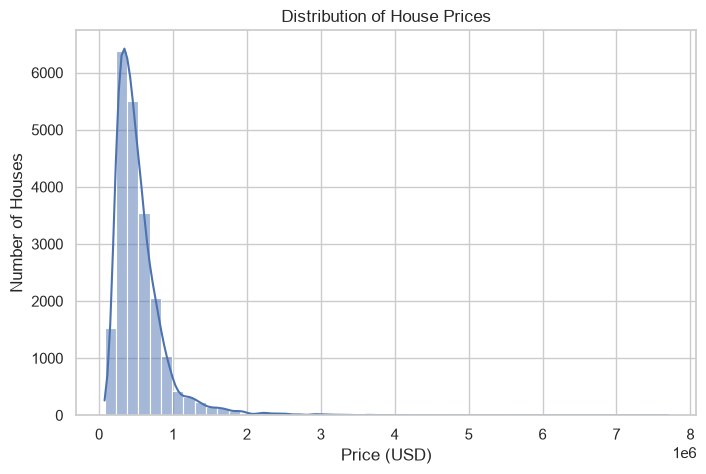

In [30]:
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Price (USD)')
plt.ylabel('Number of Houses')
plt.show()

**What I see:** Most houses cost less than about 1 million dollars. A few very expensive houses stretch the chart to the right.

### Visualization 2: Correlation heatmap

This chart shows how strongly the number columns move together. A value near 1 means a strong positive link. A value near 0 means little link.

I left out `id` because it is only a label and has no meaning for this chart.

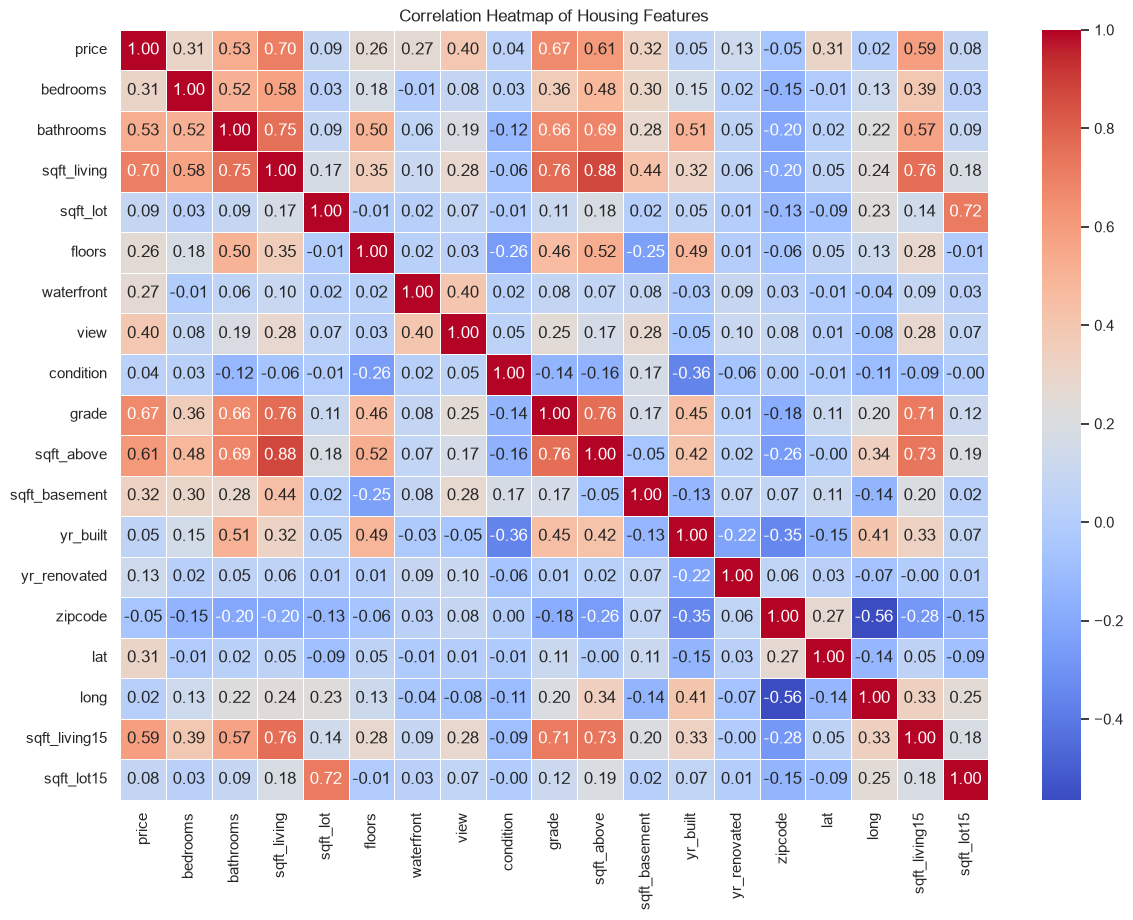

In [31]:
corr = df.drop(columns=['id']).corr(numeric_only=True)

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Housing Features')
plt.show()

**What I see:** Some features, such as living area and grade, have a strong link with `price`.

### Visualization 3: Scatter plot of the top 2 correlated features

First, I find the 2 features most strongly linked with `price`. Then I plot each one against `price`.

sqft_living    0.702035
grade          0.667434
Name: price, dtype: float64


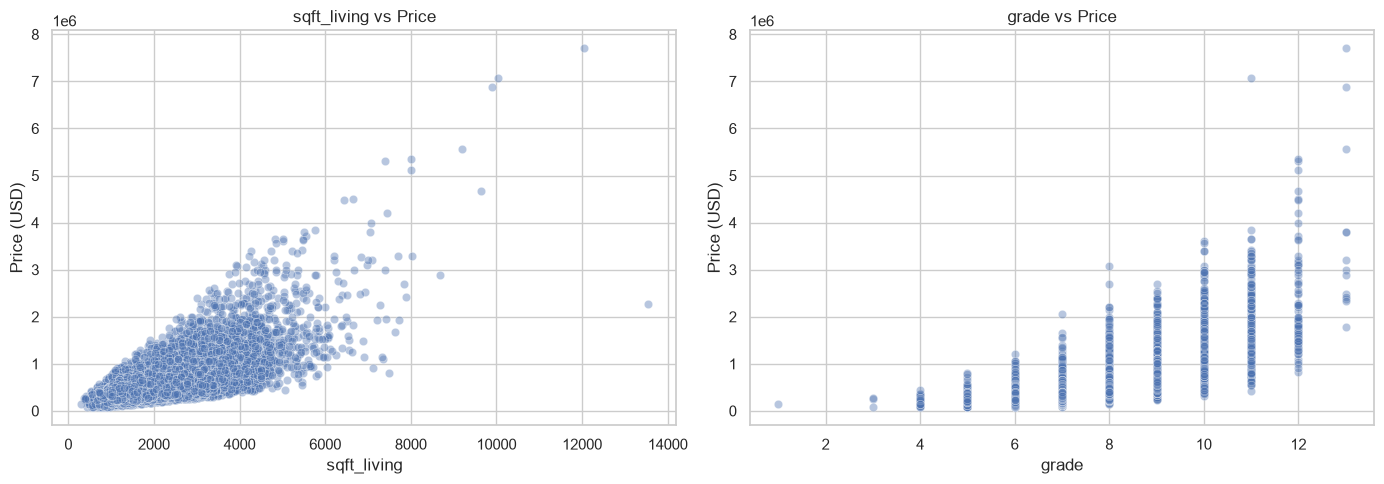

In [32]:
# Find the 2 features most linked with price
top2 = corr['price'].drop('price').sort_values(ascending=False).head(2)
print(top2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feature in zip(axes, top2.index):
    sns.scatterplot(data=df, x=feature, y='price', alpha=0.4, ax=ax)
    ax.set_title(f'{feature} vs Price')
    ax.set_xlabel(feature)
    ax.set_ylabel('Price (USD)')
plt.tight_layout()
plt.show()

**What I see:** Bigger living area and higher grade usually mean a higher price. The dots go up from left to right.

In [33]:
# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [34]:
# Inspect numerical columns
print(df.describe().T)

                 count          mean           std           min  \
id             21613.0  4.580302e+09  2.876566e+09  1.000102e+06   
price          21613.0  5.400881e+05  3.671272e+05  7.500000e+04   
bedrooms       21613.0  3.370842e+00  9.300618e-01  0.000000e+00   
bathrooms      21613.0  2.114757e+00  7.701632e-01  0.000000e+00   
sqft_living    21613.0  2.079900e+03  9.184409e+02  2.900000e+02   
sqft_lot       21613.0  1.510697e+04  4.142051e+04  5.200000e+02   
floors         21613.0  1.494309e+00  5.399889e-01  1.000000e+00   
waterfront     21613.0  7.541757e-03  8.651720e-02  0.000000e+00   
view           21613.0  2.343034e-01  7.663176e-01  0.000000e+00   
condition      21613.0  3.409430e+00  6.507430e-01  1.000000e+00   
grade          21613.0  7.656873e+00  1.175459e+00  1.000000e+00   
sqft_above     21613.0  1.788391e+03  8.280910e+02  2.900000e+02   
sqft_basement  21613.0  2.915090e+02  4.425750e+02  0.000000e+00   
yr_built       21613.0  1.971005e+03  2.937341e+

In [35]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (21613, 21)
Missing values: 0
Duplicate rows: 0


## Summary

- I loaded the housing data into a DataFrame.
- I checked the shape, data types, summary numbers and missing values.
- I handled missing values and explained when to use fill or drop.
- I made 3 labeled charts: a histogram, a heatmap and a scatter plot.